# Inflation forecasting: 2022–2025

In [15]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'modelling').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from modelling.regime_experiment import notebook_result_table, plot_notebook_forecasts, plot_predicted_regimes

RESULTS_FILE = PROJECT_ROOT / 'data/processed/model_results/results_static_2022_2025.json'
TEST_START, TEST_END = '2022-01-01', '2025-11-01'
if not RESULTS_FILE.exists():
    raise FileNotFoundError('Run `python -m modelling.regime_experiment` before opening Notebook 2.')
results = json.loads(RESULTS_FILE.read_text(encoding='utf-8'))
expected_signature = {'test_start': TEST_START, 'test_end': TEST_END, 'main_estimation': 'static'}
mismatches = {key: (results.get('signature', {}).get(key), value)
              for key, value in expected_signature.items()
              if results.get('signature', {}).get(key) != value}
if mismatches:
    raise ValueError(f'Results do not match Notebook 2 configuration: {mismatches}')
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.Series(results['sample'], name='Current comparison').to_frame())

,Current comparison
training_start,2008-07-01
initial_training_end,2021-12-01
scored_start,2022-01-01
scored_end,2025-09-01
scored_months,45
unavailable_months,"[2025-10, 2025-11]"
timing,Static coefficients estimated through December...
data_vintage,"Latest revised FRED data, not a real-time vint..."


In [16]:
def show_comparison(group):
    table = notebook_result_table(results, group)
    display(table.drop(columns='key').round(4))
    return table

def plot_rmse(table, title):
    ordered = table.sort_values('rmse', ascending=False)
    ax = ordered.plot.barh(x='model', y='rmse', legend=False, figsize=(12, max(3, .28 * len(ordered))))
    ax.set(xlabel='RMSE (percentage points)', ylabel='', title=title)
    ax.grid(axis='x', alpha=.2)
    plt.tight_layout()
    plt.show()

def matching_ar_gains(table):
    table = table.copy()
    ar = {tuple(results['models'][row.key]['features']): row.rmse
          for row in table.itertuples() if row.family == 'AR'}
    table['gain_vs_matching_AR_pct'] = [
        100 * (1 - row.rmse / ar[tuple(results['models'][row.key]['features'])])
        if row.family == 'AR-HMM' else np.nan for row in table.itertuples()
    ]
    return table

## Static baselines

,model,family,rmse,mae,mean_error_actual_minus_forecast
0,Static AR-HMM + lagged sentiment,AR-HMM,0.2615,0.1815,0.0708
1,Static AR-HMM,AR-HMM,0.2622,0.1813,0.0746
2,Static AR(1),AR,0.2637,0.1825,0.0674
3,Static ARX + sentiment,AR,0.2639,0.1830,0.0692
4,Static LASSO,LASSO,0.2671,0.1854,0.0836
5,Static LASSO + sentiment,LASSO,0.2679,0.1836,0.0994
6,Static HMM,HMM,0.3025,0.1972,0.1424


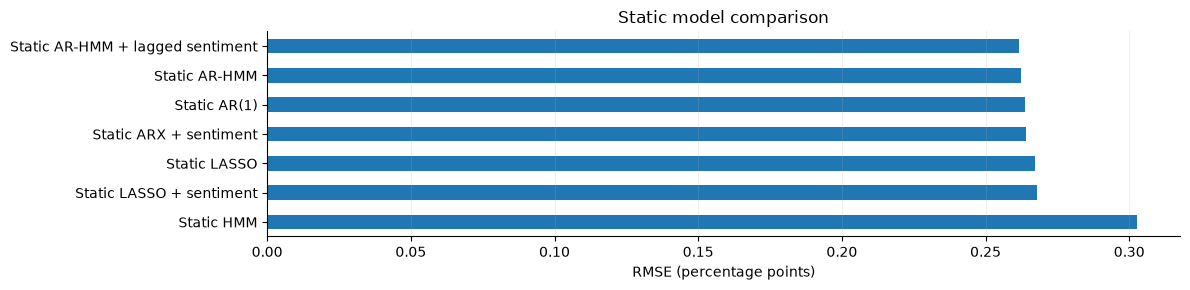

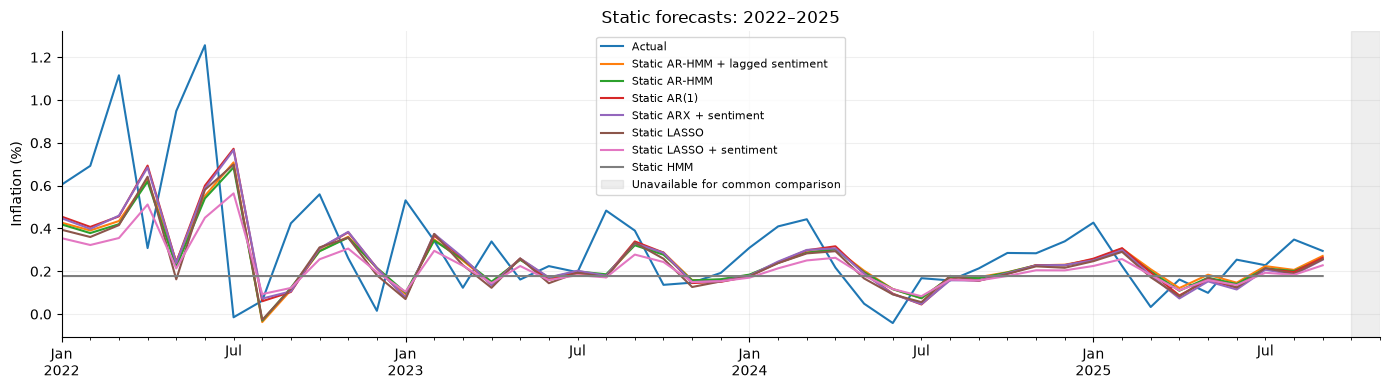

In [17]:
static_table = show_comparison('Static baselines')
plot_rmse(static_table, 'Static model comparison')
plot_notebook_forecasts(results, static_table['key'], 'Static forecasts: 2022–2025')
plt.show()

## Expanding-window effect

,model,family,rmse,mae,mean_error_actual_minus_forecast
0,Static AR-HMM,AR-HMM,0.2622,0.1813,0.0746
1,Static AR(1),AR,0.2637,0.1825,0.0674
2,Expanding AR(1),AR,0.2655,0.1817,0.0546
3,Expanding AR-HMM(1) · 2 states,AR-HMM,0.3052,0.1976,0.0459


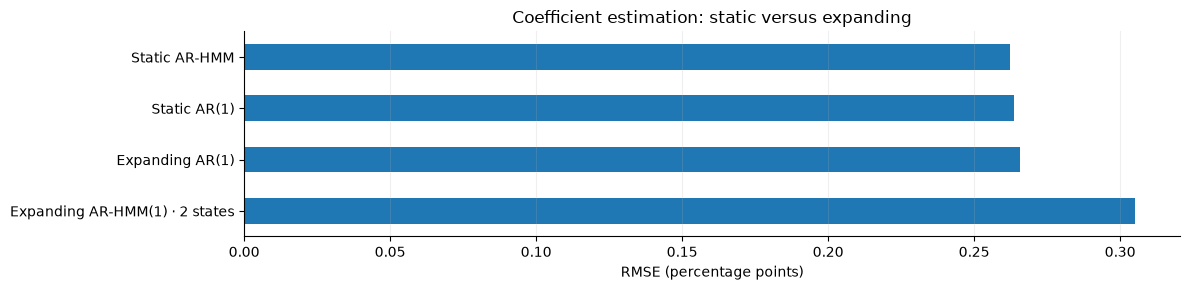

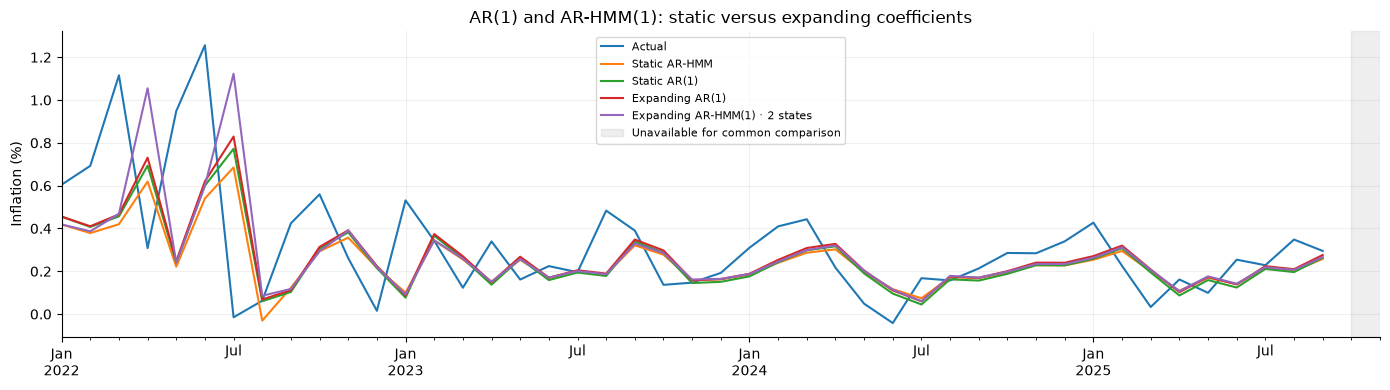

In [18]:
window_table = show_comparison('Static vs expanding')
plot_rmse(window_table, 'Coefficient estimation: static versus expanding')
plot_notebook_forecasts(results, window_table['key'], 'AR(1) and AR-HMM(1): static versus expanding coefficients')
plt.show()

## Monthly inflation: static lag orders 1–6

,model,family,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,Static AR-HMM,AR-HMM,0.2622,0.1813,0.0746,0.5908
1,Static AR(1),AR,0.2637,0.1825,0.0674,NaN
2,MoM AR-HMM(5) · 2 states,AR-HMM,0.2653,0.1801,0.0605,6.4594
3,MoM AR-HMM(4) · 2 states,AR-HMM,0.2664,0.1812,0.0658,3.8206
4,MoM AR-HMM(2) · 2 states,AR-HMM,0.2727,0.1888,0.0872,1.3240
5,MoM AR(3),AR,0.2763,0.1924,0.0854,NaN
6,MoM AR(2),AR,0.2764,0.1924,0.0854,NaN
7,MoM AR(4),AR,0.2770,0.1921,0.0798,NaN
8,MoM AR-HMM(6) · 2 states,AR-HMM,0.2777,0.1901,0.0722,2.4301
9,MoM AR(5),AR,0.2836,0.1952,0.0892,NaN


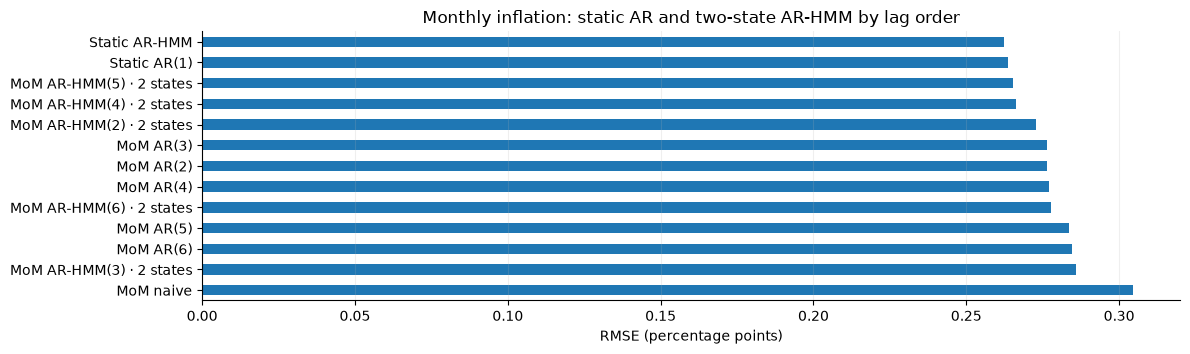

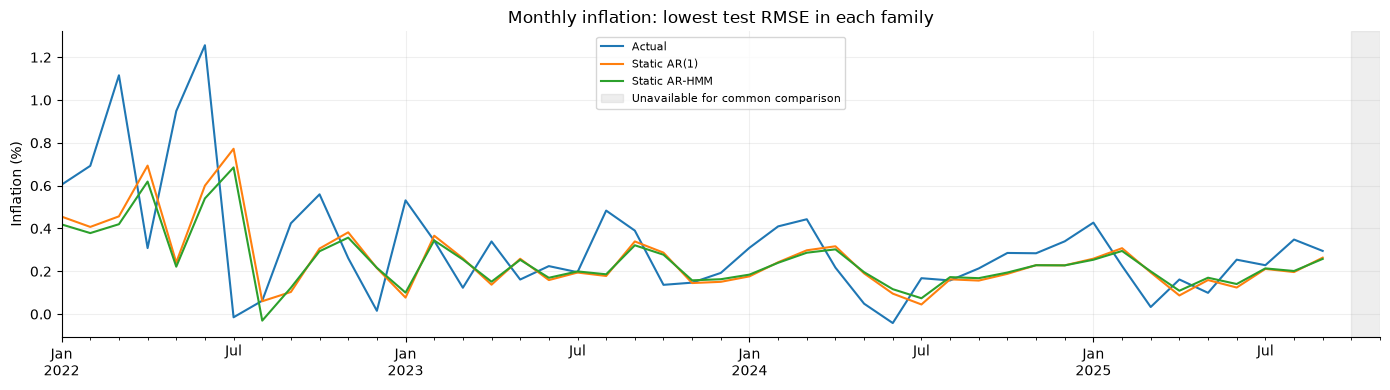

In [19]:
mom_lags = matching_ar_gains(notebook_result_table(results, 'MoM lag orders'))
display(mom_lags.drop(columns='key').round(4))
plot_rmse(mom_lags, 'Monthly inflation: static AR and two-state AR-HMM by lag order')
best_mom_keys = mom_lags.loc[mom_lags.family.isin(['AR', 'AR-HMM'])].sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_mom_keys, 'Monthly inflation: lowest test RMSE in each family')
plt.show()

## Monthly inflation: static 2, 3 and 4 states at lag 1

,model,family,rmse,mae,mean_error_actual_minus_forecast
0,Static AR-HMM,AR-HMM,0.2622,0.1813,0.0746
1,Static AR(1),AR,0.2637,0.1825,0.0674
2,MoM AR-HMM(1) · 4 states,AR-HMM,0.2734,0.1836,0.0999
3,MoM AR-HMM(1) · 3 states,AR-HMM,0.3128,0.2036,0.0642


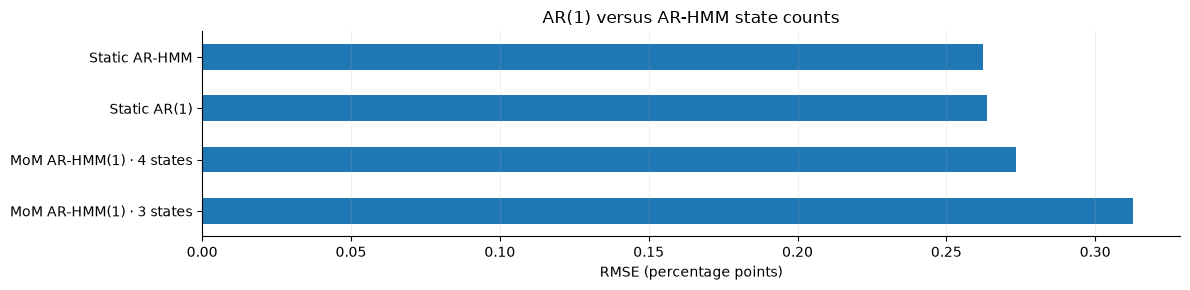

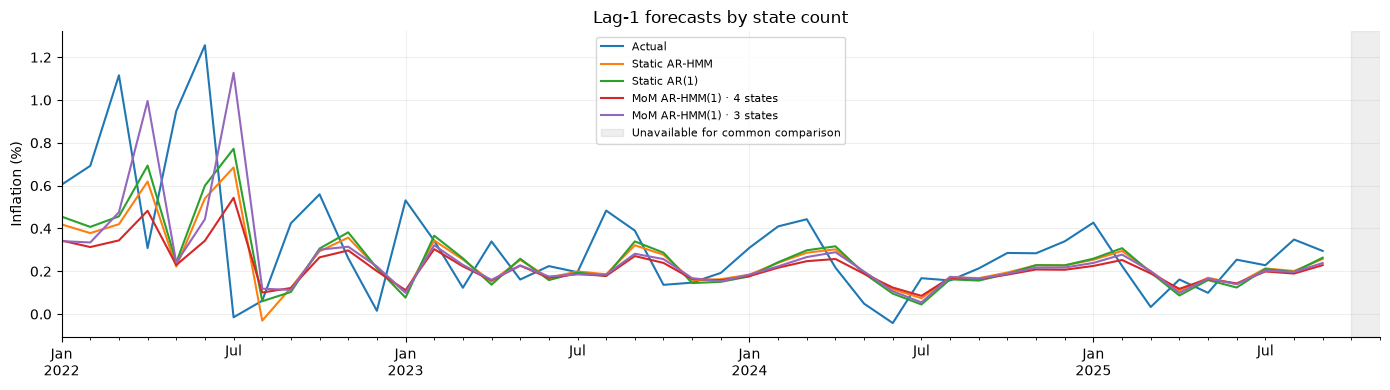

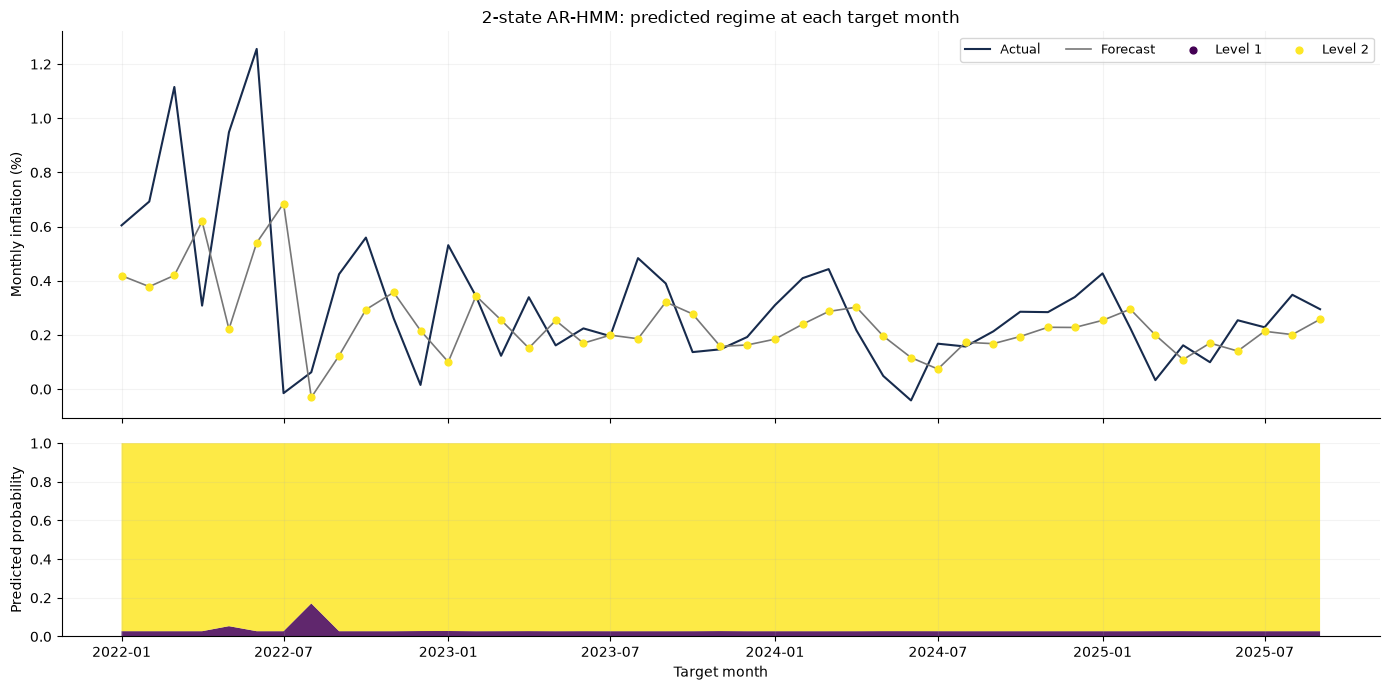

,Static AR-HMM
PredictedRegime,
Level 1,0
Level 2,45


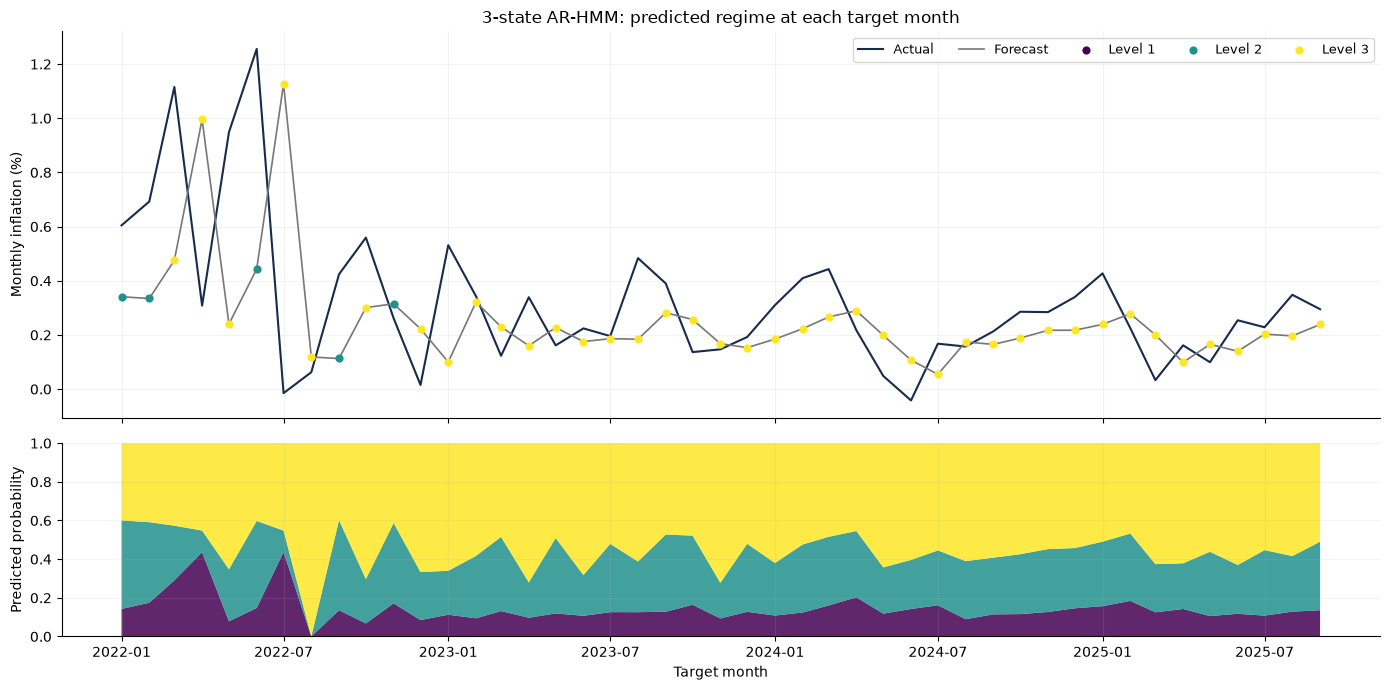

,MoM AR-HMM(1) · 3 states
PredictedRegime,
Level 1,0
Level 2,5
Level 3,40


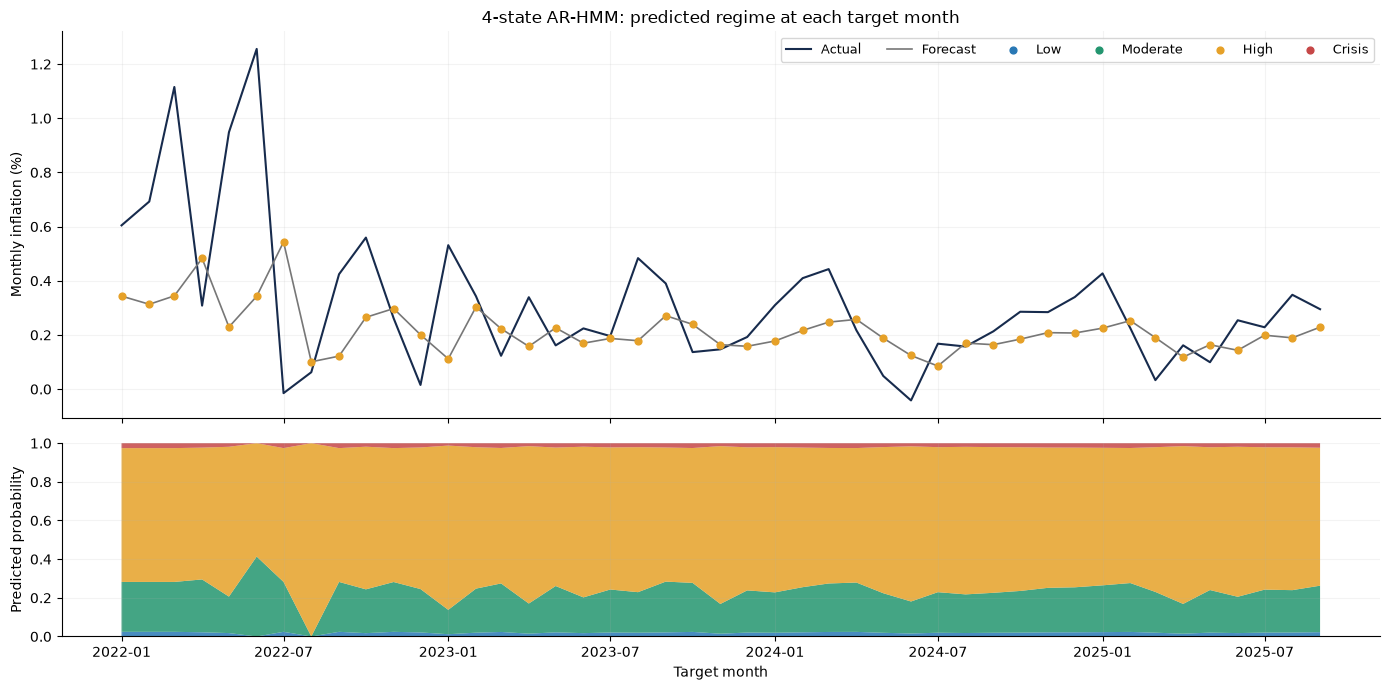

,MoM AR-HMM(1) · 4 states
PredictedRegime,
Low,0
Moderate,0
High,45
Crisis,0


In [20]:
state_table = show_comparison('MoM state counts')
plot_rmse(state_table, 'AR(1) versus AR-HMM state counts')
plot_notebook_forecasts(results, state_table['key'], 'Lag-1 forecasts by state count')
plt.show()
for key in results['groups']['MoM state counts']:
    model = results['models'][key]
    if model['family'] != 'AR-HMM':
        continue
    frame = pd.DataFrame(model['forecasts'])
    frame['Date'] = pd.to_datetime(frame['Date'])
    labels = model['parameters']['regime_labels']
    plot_predicted_regimes(frame, labels)
    plt.show()
    display(frame.PredictedRegime.value_counts().reindex(labels, fill_value=0).rename(model['name']).to_frame())

## MoM: static macroeconomic indicators

,model,family,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,MoM AR-HMM(1) + Unemployment,AR-HMM,0.2621,0.1806,0.0729,0.6993
1,Static AR-HMM,AR-HMM,0.2622,0.1813,0.0746,0.5908
2,Static AR(1),AR,0.2637,0.1825,0.0674,NaN
3,MoM AR(1) + Industry,AR,0.2638,0.1824,0.0668,NaN
4,MoM AR(1) + Unemployment,AR,0.2639,0.1825,0.0659,NaN
5,MoM AR(1) + Unemployment + Industry,AR,0.2641,0.1828,0.0662,NaN
6,MoM AR-HMM(1) + Unemployment + Industry + Fed ...,AR-HMM,0.2687,0.1898,0.0717,9.8981
7,MoM AR(1) + Oil + Fed rate,AR,0.2756,0.2046,0.0671,NaN
8,MoM AR-HMM(1) + Oil + Fed rate,AR-HMM,0.2757,0.2038,0.0851,-0.0263
9,MoM AR(1) + Oil,AR,0.2778,0.2026,0.1018,NaN


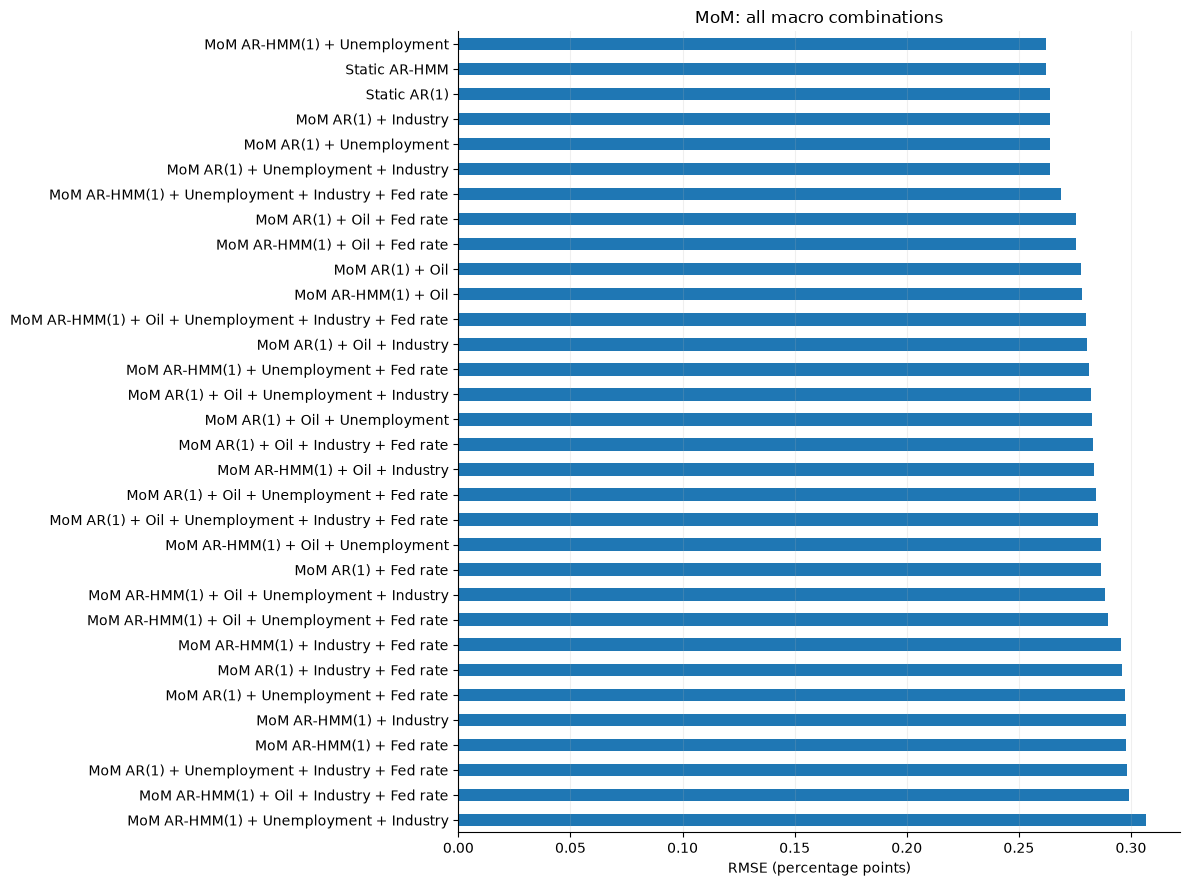

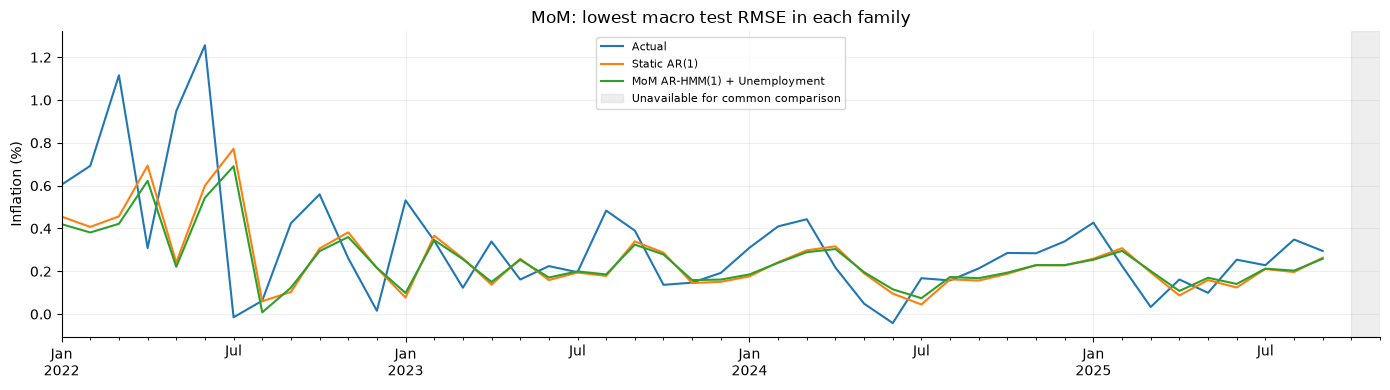

In [21]:
macro_table = matching_ar_gains(notebook_result_table(results, 'MoM macro'))
display(macro_table.drop(columns='key').round(4))
plot_rmse(macro_table, 'MoM: all macro combinations')
best_keys = macro_table.sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_keys, 'MoM: lowest macro test RMSE in each family')
plt.show()

## MoM: static sentiment with and without macro inputs

,model,family,rmse,mae,mean_error_actual_minus_forecast
0,MoM AR-HMM(1) + Unemployment,AR-HMM,0.2621,0.1806,0.0729
1,MoM AR-HMM(1) + sentiment,AR-HMM,0.2621,0.1807,0.0739
2,Static AR-HMM,AR-HMM,0.2622,0.1813,0.0746
3,Static AR(1),AR,0.2637,0.1825,0.0674
4,MoM AR(1) + Industry,AR,0.2638,0.1824,0.0668
5,Static ARX + sentiment,AR,0.2639,0.1830,0.0692
6,MoM AR(1) + Industry + sentiment,AR,0.2640,0.1831,0.0685
7,MoM AR-HMM(1) + Unemployment + sentiment,AR-HMM,0.3028,0.1965,0.0546


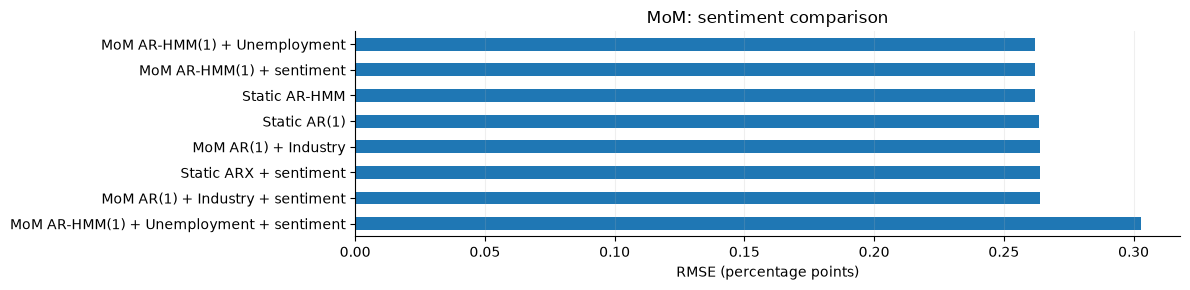

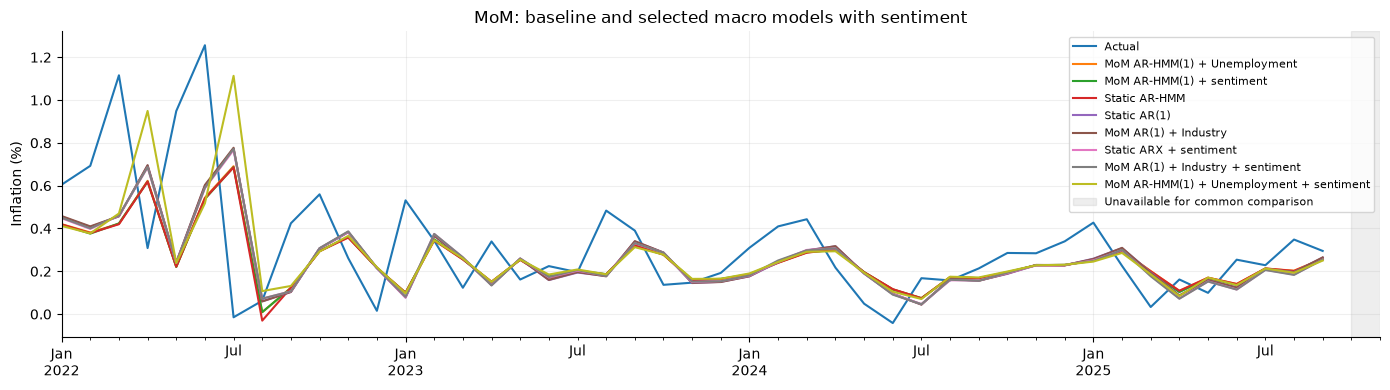

In [22]:
sentiment_table = show_comparison('MoM sentiment')
plot_rmse(sentiment_table, 'MoM: sentiment comparison')
plot_notebook_forecasts(results, sentiment_table['key'], 'MoM: baseline and selected macro models with sentiment')
plt.show()

## Monthly inflation: static alternative FinBERT aggregations

,model,family,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,MoM AR-HMM(1) + Sentiment_Median,AR-HMM,0.2600,0.1776,0.0664,1.1345
1,MoM AR(1) + Sentiment_Std,AR,0.2610,0.1807,0.0594,NaN
2,MoM AR-HMM(1) + sentiment,AR-HMM,0.2621,0.1807,0.0739,0.6886
3,Static AR-HMM,AR-HMM,0.2622,0.1813,0.0746,0.5908
4,MoM AR(1) + Sentiment_Median,AR,0.2630,0.1814,0.0631,NaN
5,MoM AR-HMM(1) + Negative_Share,AR-HMM,0.2630,0.1788,0.0640,0.1034
6,MoM AR(1) + Negative_Share,AR,0.2633,0.1819,0.0650,NaN
7,Static AR(1),AR,0.2637,0.1825,0.0674,NaN
8,Static ARX + sentiment,AR,0.2639,0.1830,0.0692,NaN
9,MoM AR-HMM(1) + Sentiment_Std,AR-HMM,0.2660,0.1821,0.0567,-1.8979


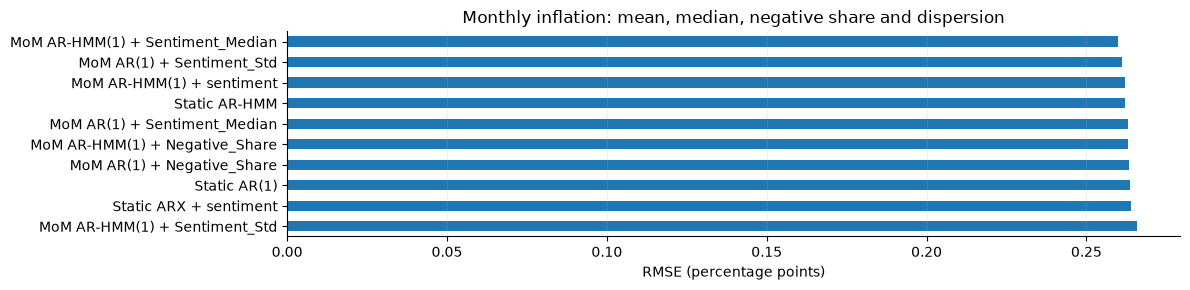

In [23]:
aggregation_table = matching_ar_gains(notebook_result_table(results, 'MoM sentiment aggregations'))
display(aggregation_table.drop(columns='key').round(4))
plot_rmse(aggregation_table, 'Monthly inflation: mean, median, negative share and dispersion')

## Year-over-year inflation: static lag orders 1–6

,model,family,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,YoY AR(1),AR,0.3781,0.2891,-0.0334,NaN
1,YoY AR-HMM(1) · 2 states,AR-HMM,0.3836,0.2943,-0.0673,-1.4627
2,YoY AR-HMM(2) · 2 states,AR-HMM,0.3871,0.3128,0.0705,9.7734
3,YoY naive,Naive,0.3911,0.2999,-0.0923,NaN
4,YoY AR-HMM(3) · 2 states,AR-HMM,0.3999,0.3175,0.0407,3.8322
5,YoY AR-HMM(5) · 2 states,AR-HMM,0.4015,0.3174,0.0842,9.8142
6,YoY AR-HMM(6) · 2 states,AR-HMM,0.4089,0.3185,0.0943,9.0216
7,YoY AR(3),AR,0.4159,0.3255,0.1412,NaN
8,YoY AR(4),AR,0.4163,0.3270,0.1359,NaN
9,YoY AR(2),AR,0.4291,0.3363,0.1769,NaN


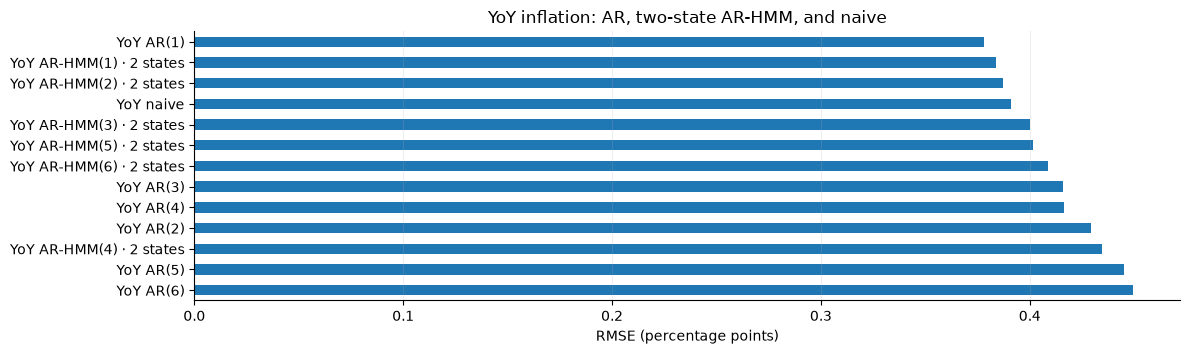

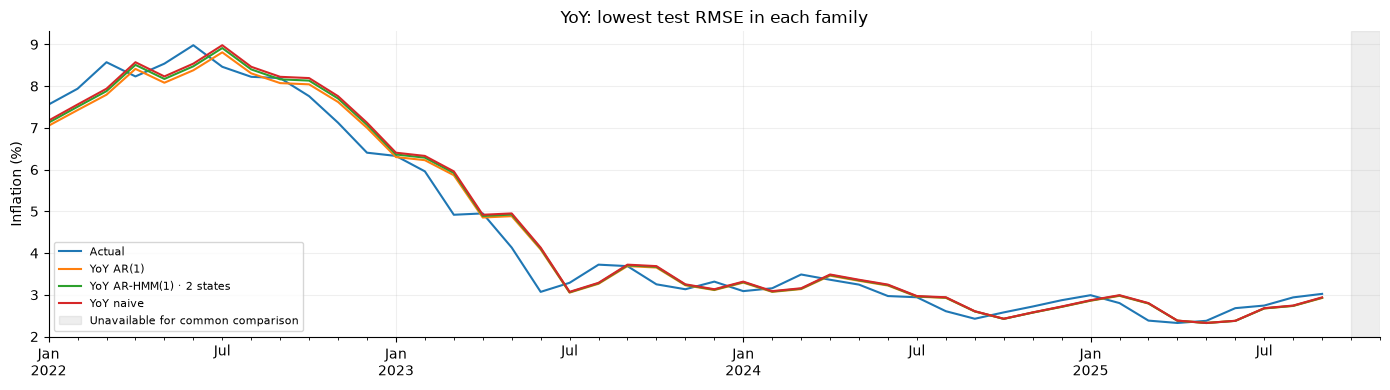

In [24]:
yoy_lags = matching_ar_gains(notebook_result_table(results, 'YoY lag orders'))
display(yoy_lags.drop(columns='key').round(4))
plot_rmse(yoy_lags, 'YoY inflation: AR, two-state AR-HMM, and naive')
best_yoy_keys = yoy_lags.loc[yoy_lags.family.isin(['AR', 'AR-HMM', 'Naive'])].sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_yoy_keys, 'YoY: lowest test RMSE in each family')
plt.show()

## YoY: static macroeconomic indicators

,model,family,rmse,mae,mean_error_actual_minus_forecast,gain_vs_matching_AR_pct
0,YoY AR-HMM(2) + Industry,AR-HMM,0.3610,0.2958,0.0612,16.0574
1,YoY AR-HMM(2) + Industry + Fed rate,AR-HMM,0.3612,0.2902,0.0811,12.4610
2,YoY AR-HMM(2) + Unemployment + Industry,AR-HMM,0.3700,0.3008,0.0645,14.0277
3,YoY AR-HMM(2) + Unemployment + Industry + Fed ...,AR-HMM,0.3714,0.2953,0.0852,10.7249
4,YoY AR-HMM(2) + Fed rate,AR-HMM,0.3767,0.2991,0.0881,7.6007
5,YoY AR-HMM(2) + Oil + Industry,AR-HMM,0.3823,0.3167,0.0518,8.3551
6,YoY AR-HMM(2) · 2 states,AR-HMM,0.3871,0.3128,0.0705,9.7734
7,YoY AR-HMM(2) + Oil + Unemployment + Fed rate,AR-HMM,0.3918,0.3109,0.0911,4.3225
8,YoY AR-HMM(2) + Unemployment,AR-HMM,0.3928,0.3146,0.0728,8.7621
9,YoY AR-HMM(2) + Oil,AR-HMM,0.3978,0.3249,0.0421,4.3856


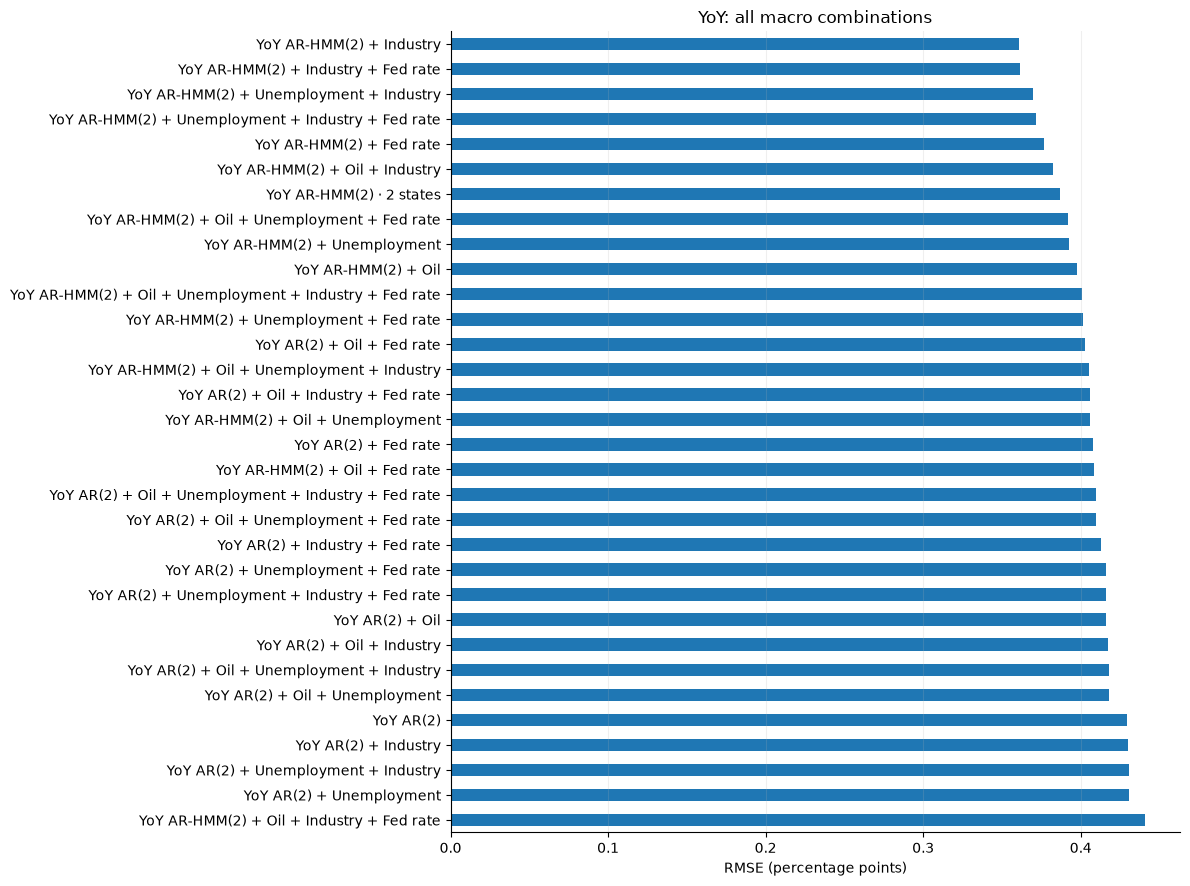

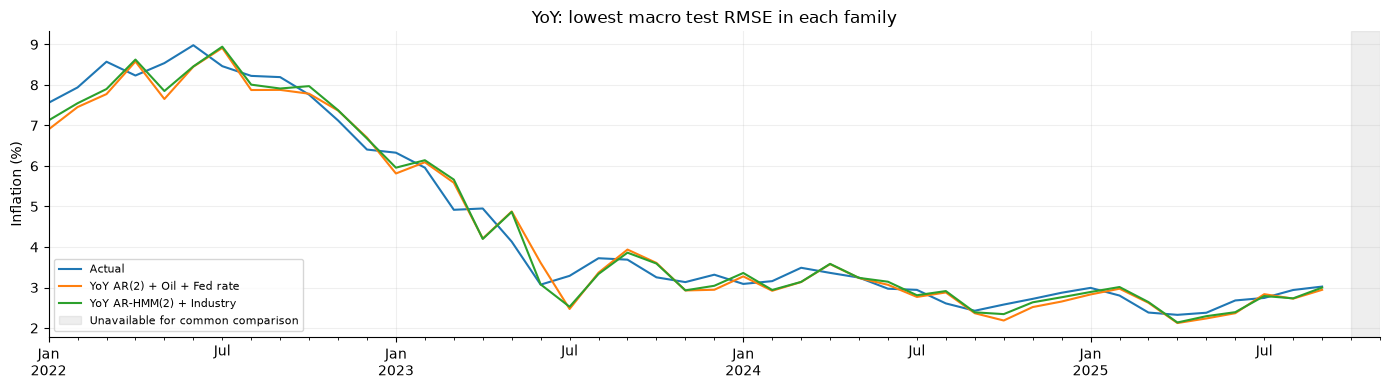

In [25]:
macro_table = matching_ar_gains(notebook_result_table(results, 'YoY macro'))
display(macro_table.drop(columns='key').round(4))
plot_rmse(macro_table, 'YoY: all macro combinations')
best_keys = macro_table.sort_values('rmse').groupby('family').first()['key'].tolist()
plot_notebook_forecasts(results, best_keys, 'YoY: lowest macro test RMSE in each family')
plt.show()

## YoY: static sentiment with and without macro inputs

,model,family,rmse,mae,mean_error_actual_minus_forecast
0,YoY AR-HMM(2) + Industry,AR-HMM,0.3610,0.2958,0.0612
1,YoY AR-HMM(2) + Industry + sentiment,AR-HMM,0.3843,0.3064,0.0753
2,YoY AR-HMM(2) · 2 states,AR-HMM,0.3871,0.3128,0.0705
3,YoY AR-HMM(2) + sentiment,AR-HMM,0.3978,0.3161,0.0788
4,YoY AR(2) + Oil + Fed rate,AR,0.4028,0.3358,0.0994
5,YoY AR(2) + Oil + Fed rate + sentiment,AR,0.4033,0.3356,0.1046
6,YoY AR(2) + sentiment,AR,0.4282,0.3342,0.1802
7,YoY AR(2),AR,0.4291,0.3363,0.1769


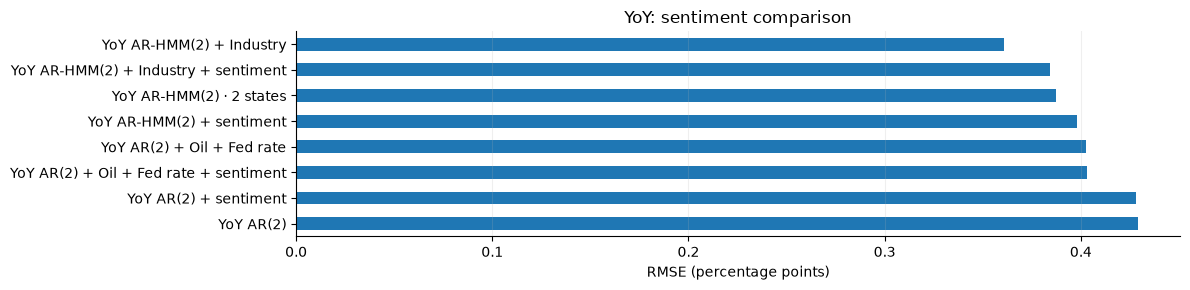

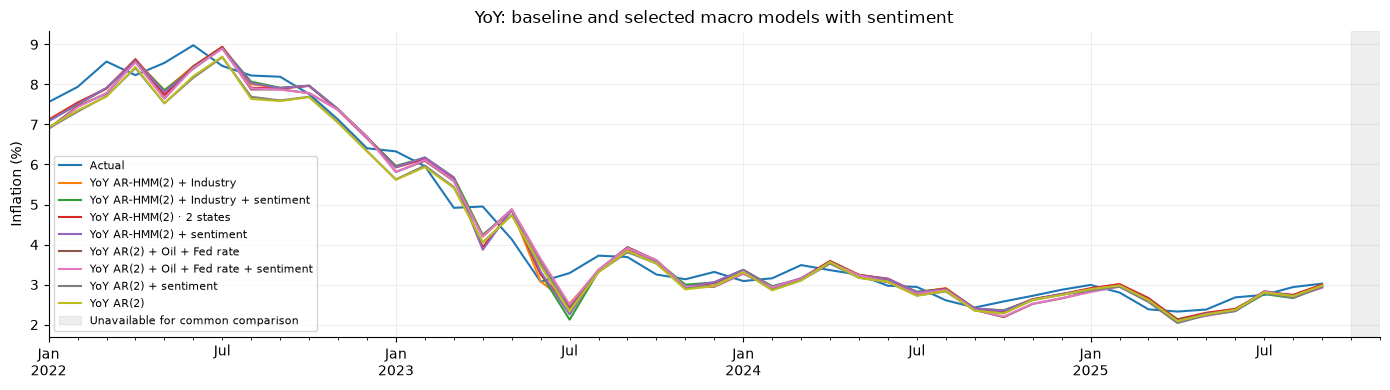

In [26]:
sentiment_table = show_comparison('YoY sentiment')
plot_rmse(sentiment_table, 'YoY: sentiment comparison')
plot_notebook_forecasts(results, sentiment_table['key'], 'YoY: baseline and selected macro models with sentiment')
plt.show()

## Overall static results

In [27]:
for target in ['Inflation_MoM', 'Inflation_YoY']:
    display(Markdown(f'**{target}**'))
    overall = pd.DataFrame([{'model': m['name'], 'estimation': m['mode'], **m['metrics']}
                            for m in results['models'].values()
                            if m['target'] == target and m['mode'] == 'static']).sort_values('rmse')
    display(overall.round(4))

**Inflation_MoM**

,model,estimation,rmse,mae,mean_error_actual_minus_forecast
56,MoM AR-HMM(1) + Sentiment_Median,static,0.2600,0.1776,0.0664
55,MoM AR(1) + Sentiment_Std,static,0.2610,0.1807,0.0594
4,Static AR-HMM + lagged sentiment,static,0.2615,0.1815,0.0708
23,MoM AR-HMM(1) + Unemployment,static,0.2621,0.1806,0.0729
51,MoM AR-HMM(1) + sentiment,static,0.2621,0.1807,0.0739
3,Static AR-HMM,static,0.2622,0.1813,0.0746
53,MoM AR(1) + Sentiment_Median,static,0.2630,0.1814,0.0631
57,MoM AR-HMM(1) + Negative_Share,static,0.2630,0.1788,0.0640
54,MoM AR(1) + Negative_Share,static,0.2633,0.1819,0.0650
0,Static AR(1),static,0.2637,0.1825,0.0674


**Inflation_YoY**

,model,estimation,rmse,mae,mean_error_actual_minus_forecast
18,YoY AR-HMM(2) + Industry,static,0.3610,0.2958,0.0612
32,YoY AR-HMM(2) + Industry + Fed rate,static,0.3612,0.2902,0.0811
28,YoY AR-HMM(2) + Unemployment + Industry,static,0.3700,0.3008,0.0645
40,YoY AR-HMM(2) + Unemployment + Industry + Fed ...,static,0.3714,0.2953,0.0852
20,YoY AR-HMM(2) + Fed rate,static,0.3767,0.2991,0.0881
0,YoY AR(1),static,0.3781,0.2891,-0.0334
24,YoY AR-HMM(2) + Oil + Industry,static,0.3823,0.3167,0.0518
1,YoY AR-HMM(1) · 2 states,static,0.3836,0.2943,-0.0673
46,YoY AR-HMM(2) + Industry + sentiment,static,0.3843,0.3064,0.0753
3,YoY AR-HMM(2) · 2 states,static,0.3871,0.3128,0.0705
